# Figure 6 — corrected metabolic evidence and patient response

The A4 portrait main figure has five plot rows and a narrow key strip: A treatment overlap, B pathway enrichment, C task-score concordance; D myeloid selenocystathionine, E–G three paired myeloid purine-node boxplots, H myeloid L-cystathionine; I–J myeloid aspartate-linked nodes, K myeloid methylglyoxal, L–M epithelial fatty acid activation, N myeloid carnitine-shuttle pathway, O myeloid L-octanoylcarnitine UMAP, P its paired activity scores, Q–S named P3-only pathway-score violins, and T paired lipid-pathway heatmap. The seven matched patients are the biological replicates for treatment comparisons; only P3 has recurrence. Staged plot tables are checksummed.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from main_A_G_plotting import load_data, make_panel, make_compiled, export, export_compiled
DATA_ROOT = Path('data')
PANEL_ROOT = Path('outputs/panels')
COMPILED_STEM = Path('outputs/Figure_6')
tables = load_data(DATA_ROOT)
assert len(tables['surgery_pathway_enrichment.csv']) == 21
assert len(tables['status_pathway_enrichment.csv']) == 33
display(tables['fig6_main_patient_stats.csv'][['panel','celltype','node','patients_lower_at_surgery','median_paired_delta','paired_wilcoxon_two_sided_unadjusted_p','pathway_screen_BH_q']])

,panel,celltype,node,patients_lower_at_surgery,median_paired_delta,paired_wilcoxon_two_sided_unadjusted_p,pathway_screen_BH_q
0,D,Myeloid,selenocystathionine,6,-0.050592,0.031250,NaN
1,E,Myeloid,adenine,7,-0.047710,0.015625,0.187500
2,E,Myeloid,guanine,6,-0.064454,0.031250,0.187500
3,E,Myeloid,deoxyinosine,6,-0.039182,0.046875,0.254032
4,F,Myeloid,L_cystathionine,7,-0.031906,0.015625,0.161337
5,G,Myeloid,3_sulfinoalanine,7,-0.018854,0.015625,0.169057
6,G,Myeloid,S_2_aminobutanoate,7,-0.053470,0.015625,0.169057
7,H,Myeloid,methylglyoxal,6,-0.029748,0.046875,0.272029


## Panel sequence

Top row: A treatment overlap → B corrected treatment pathways → C pooled task-score concordance. Second row: D myeloid selenocystathionine → E–G three paired myeloid purine-node boxplots on a shared score scale → H myeloid L-cystathionine → I myeloid 3-sulfinoalanine. Third row: J myeloid (S)-2-aminobutanoate → K myeloid methylglyoxal → L–M epithelial fatty acid activation → N myeloid peroxisomal carnitine shuttle. Fourth row: O myeloid L-octanoylcarnitine UMAP → P paired node activity → Q–S three P3 pathway-score violins. Fifth row: T full-width paired biopsy–surgery lipid-pathway heatmap. A narrow strip below carries patient and outcome-status keys. Compiled titles are shortened where needed; the legend retains full names and statistics. The frozen data retain their earlier panel codes; the export manifest records each display-to-source mapping. All Figure 6 cell groups are Wu SingleR major calls joined by cell ID. Supplementary Figure S6 A–F shows metastatic-status pathway context, carnitine-node UMAPs, two additional carnitine nodes, and the surgery-time lipid heatmap.

## LC–MS-linked node screen for D–K

The complete screen uses shared Human-GEM reaction membership and the Figure 4 Wu major calls. It tests each scored node in each of six compartments with seven patient medians; BH correction is retained both across all unique node–cell tests and within each mapped LC–MS pathway. D is selenium/sulfur biochemical context, not a direct selenoamino-acid graph match. Selected patient-level plots are exploratory and do not establish metabolite concentration or flux. I–K show only the seven matched biopsy and surgery patient medians. The separate P3 node recurrence records are retained as analysis provenance and are not plotted.

In [2]:
bridge = tables['lcms_node_pathway_screen.csv']
assert len(bridge) == 1800
assert bridge[['celltype','node']].drop_duplicates().shape[0] == 1344
assert bridge.global_node_cell_BH_q.min() > .05
display(bridge.groupby('pathway').agg(tests=('node','size'),minimum_q=('pathway_screen_BH_q','min')))

,tests,minimum_q
pathway,,
Aspartate and asparagine metabolism,330,0.169057
Glycolysis and Gluconeogenesis,354,0.194079
Methionine and cysteine metabolism,444,0.161337
Purine metabolism,672,0.187500


## Independent task/pathway analysis for L–N and Q–T

The source is the 69,390-cell separately compositional MEIA matrix aligned by exact cell ID to patient, timepoint and Figure 4 Wu SingleR major call. For each score, one cell median per patient–timepoint–cell type is used. The seven paired Surgery−Biopsy medians enter an exact two-sided Wilcoxon signed-rank test; BH correction is applied separately across 1,308 task–cell-type and 828 pathway–cell-type comparisons among the six prespecified Wu major groups. The full eight-group Wu screen is retained as sensitivity data; L–N display two epithelial fatty acid activation pathways and the myeloid carnitine shuttle. The two former PVL task selections remain in the staged analysis table as provenance but are not displayed. P3 cell-level distributions for these pathways are shown separately in Q–S; dots mark specimen medians and a dark line joins the three medians within each pathway. T summarizes twelve lipid pathways across six Wu compartments using the median of seven patient-level log2 surgery/biopsy ratios. This analysis does not require LC–MS matching. P3 is the only patient with a recurrence specimen, so recurrence has no patient-level p value.

In [3]:
screen = pd.read_csv(DATA_ROOT / 'recurrence_task_pathway_screen.csv')
selected = tables['lipid_trajectory_summary.csv']
assert len(screen) == 2136 and screen.score_family.value_counts().to_dict() == {'task': 1308, 'pathway': 828}
assert selected.panel.tolist() == list('LMN')
display(selected[['panel','celltype','score_name','patients_in_treatment_direction','paired_wilcoxon_two_sided_p','treatment_BH_FDR','p3_biopsy_median','p3_surgery_median','p3_recurrence_median','p3_recovery_fraction']])
display(screen.groupby('score_family').agg(tests=('score_name','size'),minimum_treatment_BH_FDR=('treatment_BH_FDR','min'),descriptive_candidates=('descriptive_rebound_candidate','sum')))

,panel,celltype,score_name,patients_in_treatment_direction,paired_wilcoxon_two_sided_p,treatment_BH_FDR,p3_biopsy_median,p3_surgery_median,p3_recurrence_median,p3_recovery_fraction
0,L,Epithelial,Fatty_acid_activation_cytosolic,7,0.015625,0.507353,0.007322,0.007747,0.009378,-3.838166
1,M,Epithelial,Fatty_acid_activation_endoplasmic_reticular,7,0.015625,0.507353,0.007479,0.007879,0.009787,-4.767551
2,N,Myeloid,Carnitine_shuttle_peroxisomal,6,0.046875,0.524493,0.005844,0.004595,0.005847,1.002590


,tests,minimum_treatment_BH_FDR,descriptive_candidates
score_family,,,
pathway,828,0.507353,42
task,1308,0.425781,37


## Myeloid carnitine node for O–P and Table 6E

The three nodes are direct scKNIFE inferred activity scores, aggregated to patient–timepoint myeloid medians. O shows L-octanoylcarnitine on the frozen Figure 4 UMAP; P shows its paired patient-median boxes; L-carnitine and octanoyl-CoA patient values are retained in Supplemental Table 6E. Treatment p values are exact two-sided paired Wilcoxon tests across seven patients. The focused BH family contains 10 graph-participant nodes × six major cell types (60 tests); it is distinct from the broader MEIA pathway screen. P3 alone has recurrence and is descriptive. The saved graph subset remains in the data package as analysis provenance.

In [4]:
display(tables['carnitine_panel_summary.csv'])
display(tables['carnitine_p3_trajectory.csv'])  # analysis provenance; not a main panel
assert len(tables['carnitine_focused_family.csv']) == 60
assert tables['carnitine_focused_family.csv'].focused_60_test_BH_q.min() > 0.05

,panel,celltype,node,biopsy_patient_median,surgery_patient_median,patients_lower_at_surgery,median_paired_delta,paired_wilcoxon_two_sided_nominal_p,focused_60_test_BH_q
0,K,Myeloid,L_carnitine,0.430402,0.340642,6,-0.030112,0.031250,0.144231
1,L,Myeloid,L_octanoylcarnitine,0.434463,0.322118,7,-0.032778,0.015625,0.144231
2,M,Myeloid,octanoyl_CoA,0.528189,0.415697,5,-0.049009,0.078125,0.275735


,use,PatientID,celltype,node,Timepoint,patient_median
0,analysis_provenance,P3,Myeloid,L_carnitine,Bx,0.376362
1,analysis_provenance,P3,Myeloid,L_carnitine,Surgery,0.381945
2,analysis_provenance,P3,Myeloid,L_carnitine,Recurrence,0.350829


## Surgery-time lipid pathway specificity retained in Table 6G

For each of ten biologically selected Human-GEM lipid pathways and seven patients, the six surgery-time cell-type medians are z-scored across cell types. Table 6G retains the equal-weight mean of those ten z-scores for each patient and cell type. The table also retains the mean z-score across seven patients per cell type. No participant bars, p-value row, or treatment comparison is shown. These separately compositional MEIA scores are inferred relative activity, not measured lipid abundance or flux. The separate twelve-pathway biopsy-to-surgery summary is displayed in main T.

In [5]:
assert len(tables['lipid_pathway_patient_values.csv']) == 420
assert len(tables['lipid_pathway_summary.csv']) == 60
assert len(tables['lipid_pathway_specificity.csv']) == 42
assert len(tables['lipid_change_12_patient_values.csv']) == 504
assert len(tables['lipid_change_12_summary.csv']) == 72
assert len(tables['p3_lipid_cell_scores.csv.gz']) == 8918
assert tables['lipid_pathway_summary.csv'].screen_wide_pathway_BH_q.min() > 0.05
display(tables['lipid_pathway_specificity.csv'].head())

,PatientID,celltype,mean_pathway_z,pathways_averaged,timepoint
0,P1,CAF,-0.442394,10,Surgery
1,P1,Endothelial,0.758889,10,Surgery
2,P1,Epithelial,0.314221,10,Surgery
3,P1,Myeloid,-0.547708,10,Surgery
4,P1,PVL,-0.352211,10,Surgery


## Figure 6A — Treatment four-set metabolic overlap

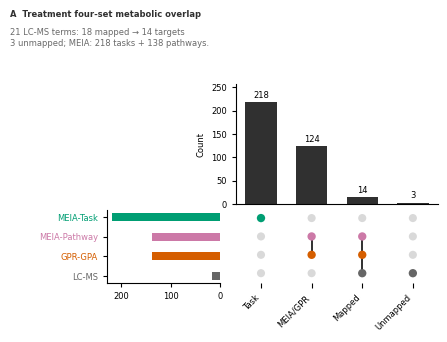

In [6]:
fig = make_panel('A', tables)
export(fig, PANEL_ROOT / 'Figure_6_A')
display(fig)
plt.close(fig)

## Figure 6B — Treatment-associated pathway enrichment

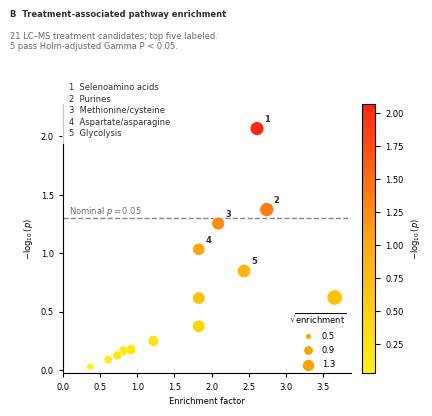

In [7]:
fig = make_panel('B', tables)
export(fig, PANEL_ROOT / 'Figure_6_B')
display(fig)
plt.close(fig)

## Figure 6C — Pooled task-score concordance

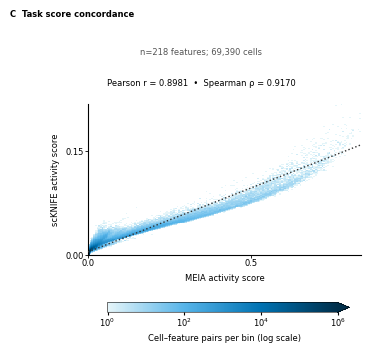

In [8]:
fig = make_panel('C', tables)
export(fig, PANEL_ROOT / 'Figure_6_C')
display(fig)
plt.close(fig)

## Figure 6D — Myeloid selenocystathionine inferred activity

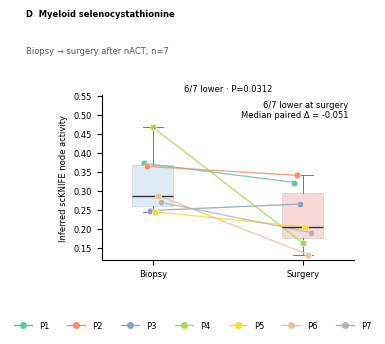

In [9]:
fig = make_panel('D', tables)
export(fig, PANEL_ROOT / 'Figure_6_D')
display(fig)
plt.close(fig)

## Figure 6E — Myeloid adenine inferred activity

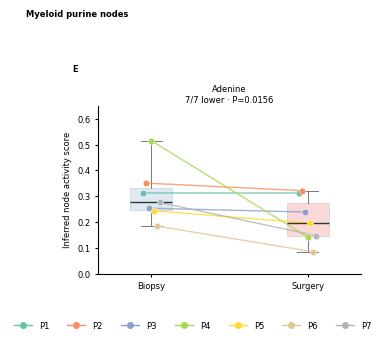

In [10]:
fig = make_panel('E', tables)
export(fig, PANEL_ROOT / 'Figure_6_E')
display(fig)
plt.close(fig)

## Figure 6F — Myeloid guanine inferred activity

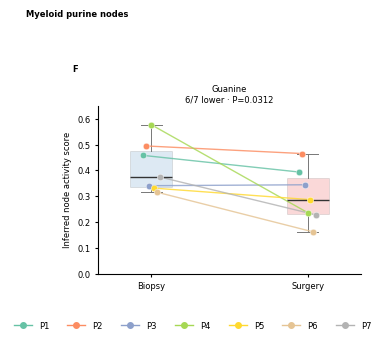

In [11]:
fig = make_panel('F', tables)
export(fig, PANEL_ROOT / 'Figure_6_F')
display(fig)
plt.close(fig)

## Figure 6G — Myeloid deoxyinosine inferred activity

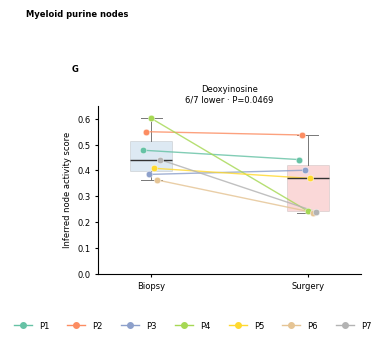

In [12]:
fig = make_panel('G', tables)
export(fig, PANEL_ROOT / 'Figure_6_G')
display(fig)
plt.close(fig)

## Figure 6H — Myeloid L-cystathionine inferred activity

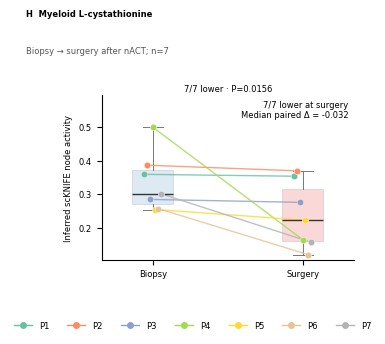

In [13]:
fig = make_panel('H', tables)
export(fig, PANEL_ROOT / 'Figure_6_H')
display(fig)
plt.close(fig)

## Figure 6I — Myeloid 3-sulfinoalanine inferred activity

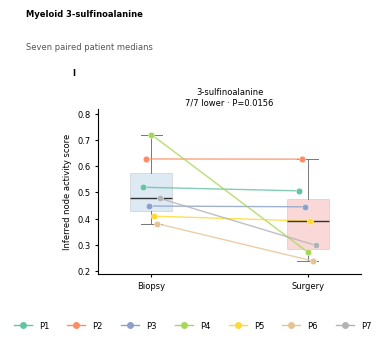

In [14]:
fig = make_panel('I', tables)
export(fig, PANEL_ROOT / 'Figure_6_I')
display(fig)
plt.close(fig)

## Figure 6J — Myeloid (S)-2-aminobutanoate inferred activity

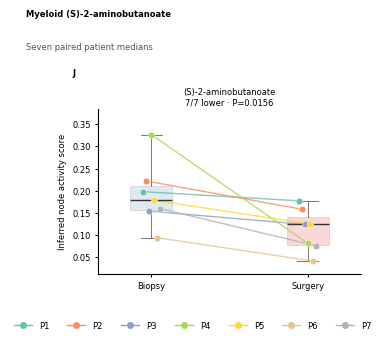

In [15]:
fig = make_panel('J', tables)
export(fig, PANEL_ROOT / 'Figure_6_J')
display(fig)
plt.close(fig)

## Figure 6K — Myeloid methylglyoxal inferred activity

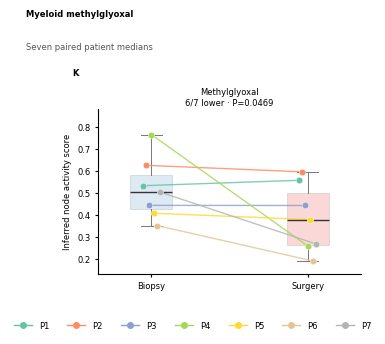

In [16]:
fig = make_panel('K', tables)
export(fig, PANEL_ROOT / 'Figure_6_K')
display(fig)
plt.close(fig)

## Figure 6L — Epithelial cytosolic fatty acid activation

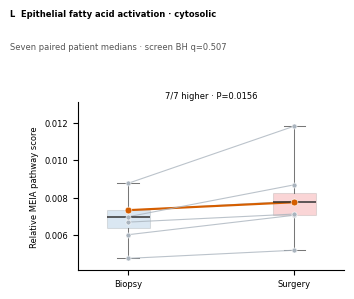

In [17]:
fig = make_panel('L', tables)
export(fig, PANEL_ROOT / 'Figure_6_L')
display(fig)
plt.close(fig)

## Figure 6M — Epithelial ER fatty acid activation

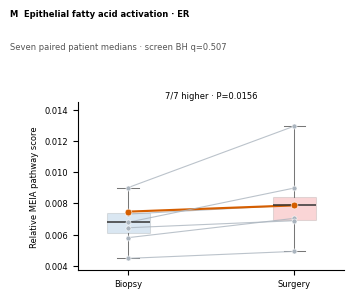

In [18]:
fig = make_panel('M', tables)
export(fig, PANEL_ROOT / 'Figure_6_M')
display(fig)
plt.close(fig)

## Figure 6N — Myeloid peroxisomal carnitine shuttle

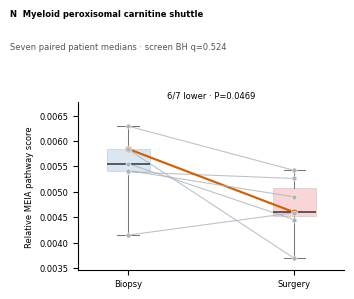

In [19]:
fig = make_panel('N', tables)
export(fig, PANEL_ROOT / 'Figure_6_N')
display(fig)
plt.close(fig)

## Figure 6O — Myeloid L-octanoylcarnitine activity UMAP

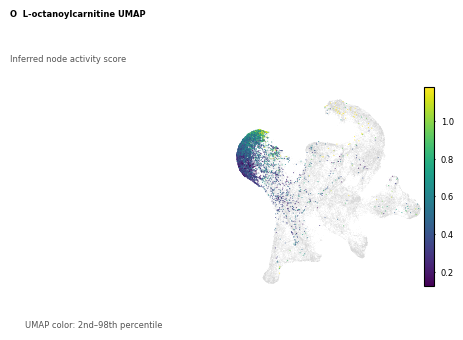

In [20]:
fig = make_panel('O', tables)
export(fig, PANEL_ROOT / 'Figure_6_O')
display(fig)
plt.close(fig)

## Figure 6P — Paired Myeloid L-octanoylcarnitine node activity

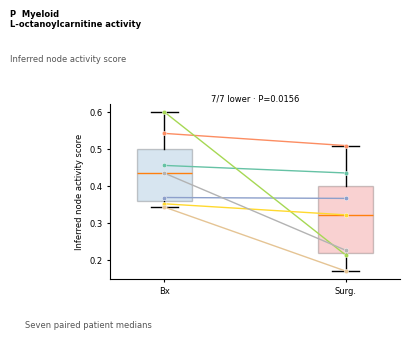

In [21]:
fig = make_panel('P', tables)
export(fig, PANEL_ROOT / 'Figure_6_P')
display(fig)
plt.close(fig)

## Figure 6Q — P3 Epithelial cytosolic fatty acid activation pathway activity

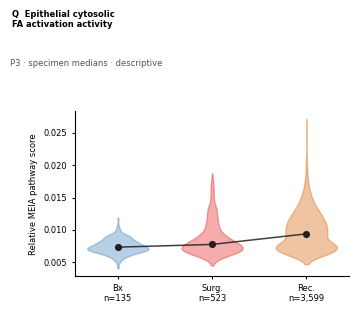

In [22]:
fig = make_panel('Q', tables)
export(fig, PANEL_ROOT / 'Figure_6_Q')
display(fig)
plt.close(fig)

## Figure 6R — P3 Epithelial ER fatty acid activation pathway activity

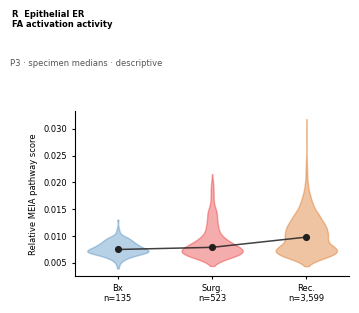

In [23]:
fig = make_panel('R', tables)
export(fig, PANEL_ROOT / 'Figure_6_R')
display(fig)
plt.close(fig)

## Figure 6S — P3 Myeloid peroxisomal carnitine-shuttle pathway activity

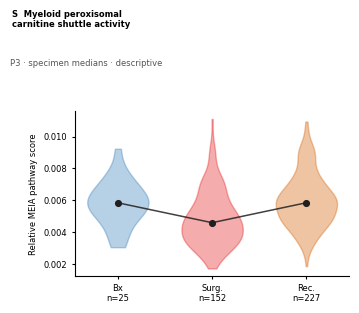

In [24]:
fig = make_panel('S', tables)
export(fig, PANEL_ROOT / 'Figure_6_S')
display(fig)
plt.close(fig)

## Figure 6T — Paired lipid pathway activity changes across Wu-major cell types

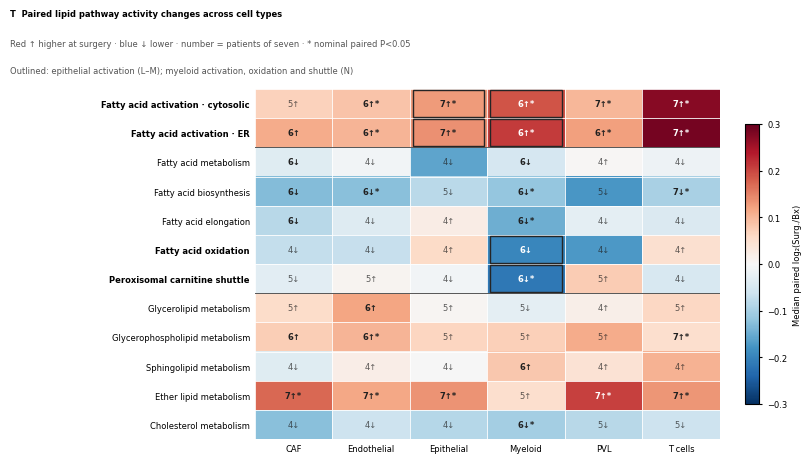

In [25]:
fig = make_panel('T', tables)
export(fig, PANEL_ROOT / 'Figure_6_T')
display(fig)
plt.close(fig)

## Compiled main figure

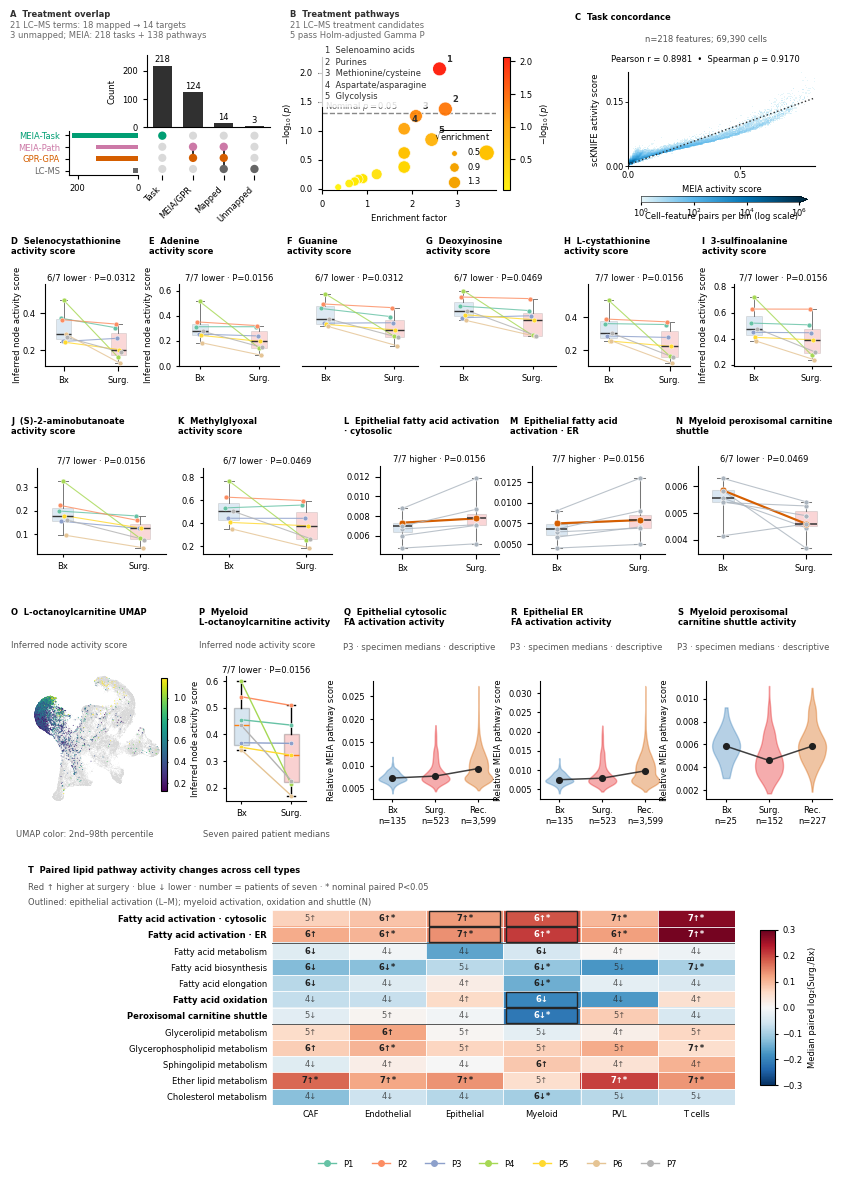

In [26]:
fig = make_compiled(tables)
export_compiled(fig, COMPILED_STEM)
display(fig)
plt.close(fig)

## Evidence limits

A–B concern analytical coverage and LC–MS pathway enrichment; enrichment is not a directional pathway test. C is technical concordance from related MEIA and scKNIFE inputs, not independent molecular validation. D–K show inferred node activity, not measured metabolite concentrations, production, secretion, or flux. E–G and I–K participate in Human-GEM reactions linked to the corresponding LC–MS pathway terms; D remains selenium/sulfur biochemical context. The selected node comparisons are post-selection. The complete node screen and its pathway and global BH q values are staged. L–N show inferred relative MEIA pathway scores. Light boxes summarize seven patient medians; all three treatment p values are nominal and screen-wide BH q values exceed 0.05. D–K use consistent biopsy/surgery boxes and the same patient-specific colors for paired points and lines. E–G retain a shared node-score scale; other node scores use their own displayed ranges. Q–S display three descriptive cell-score distributions from the one patient with recurrence; each thin line connects specimen medians within one pathway, and there is no recurrence p value. O maps a connected myeloid carnitine node; P shows its seven paired patient medians; its focused-family BH q exceeds 0.05. P3's pathway-level carnitine score returns toward its biopsy value, but that is not a matched node-level rebound. T shows paired changes for twelve inferred lipid pathways; Table 6G retains the separate surgery-time ten-pathway specificity summary. The two additional carnitine-node patient summaries are in Table 6E. Direct Human-GEM pathway participation does not identify any LC–MS feature as these nodes.